# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** [Fardho Zurrahman]
- **Email:** [zurrahmanfardho0@gmail.com]
- **ID Dicoding:** [vardhoo]


## Menentukan Pertanyaan Bisnis

- Bagaimana pengaruh kondisi cuaca terhadap jumlah penyewaan sepeda harian selama tahun 2012?
- Bagaimana pola penyewaan sepeda berdasarkan waktu (jam) pada hari kerja dan akhir pekan selama tahun 2012?

## Import Semua Packages/Library yang Digunakan

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
import scipy.stats as stats
import warnings


## Data Wrangling

### Gathering Data

In [51]:
# load data_1
day_df = pd.read_csv('data/day.csv')
day_df

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247,1867,2114
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644,2451,3095
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796


In [52]:
# load data_2
hour_df = pd.read_csv('data/hour.csv')
hour_df

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61


In [53]:
# cek struktur data_1
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [54]:
# cek struktur data_2
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [55]:
# statistik desktriptif data_1
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [56]:
# statistik deskriptif data_2
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Insight:**
- Dataset yang digunakan dalam analisis ini terdiri dari dua file utama, yaitu day.csv dan hour.csv.
- Dataset day.csv berisi data agregasi harian, yang mana setiap baris merepresentasikan satu hari. Dataset ini memiliki beberapa variabel penting :
_1 Informasi waktu: dteday, yr, mnth, weekday
Informasi kondisi: season, holiday, workingday, weathersit
_2 Variabel cuaca: temp, atemp, hum, windspeed
Informasi penyewaan: casual, registered, dan cnt sebagai total penyewaan
- Dataset hour.csv memiliki struktur yang mirip dengan day.csv, namun dengan tingkat yang lebih detail, yaitu per jam. Dataset ini mencakup tambahan variabel hr yang menunjukkan jam dalam satu hari, sehingga memungkinkan analisis pola penyewaan sepeda secara lebih rinci berdasarkan waktu.
- Berdasarkan hasil pemeriksaan struktur data menggunakan .info(), kedua dataset memiliki jumlah kolom yang lengkap dan tipe data yang sesuai, yang terdiri dari data numerik dan kategorikal.
- Selain itu, terdapat beberapa variabel kategorikal yang masih direpresentasikan dalam bentuk angka, seperti season dan weathersit, yang nantinya perlu dilakukan transformasi agar lebih mudah dipahami pada tahap analisis dan visualisasi.
- Secara keseluruhan, data yang diperoleh telah terstruktur dengan baik dan siap untuk dilanjutkan ke tahap pemeriksaan kualitas data (assessing) dan eksplorasi lebih lanjut.

### Assessing Data

In [57]:
# cek missing value_1
day_df.isnull().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [58]:
# cek missing value_2
hour_df.isnull().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


In [59]:
# cek duplikasi_1
day_df.duplicated().sum()

np.int64(0)

In [60]:
# cek duplikasi_2
hour_df.duplicated().sum()

np.int64(0)

In [61]:
# cek tipe data_1
day_df.dtypes

,0
instant,int64
dteday,object
season,int64
yr,int64
mnth,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64
temp,float64


In [62]:
# cek tipe data_2
hour_df.dtypes

,0
instant,int64
dteday,object
season,int64
yr,int64
mnth,int64
hr,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64


In [63]:
# cek nilai unik
day_df['season'].unique()

array([1, 2, 3, 4])

In [64]:
# cek nilai unik
day_df['weathersit'].unique()

array([2, 1, 3])

In [65]:
# cek nilai unik
hour_df['hr'].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23])

**Insight:**
- Tidak ditemukan missing values pada seluruh kolom di kedua dataset, yang ditunjukkan dengan nilai nol pada setiap kolom. Hal ini menunjukkan bahwa data telah lengkap dan tidak memerlukan penanganan terhadap nilai yang hilang.
- Tidak terdapat data duplikat pada kedua dataset, sehingga dapat dipastikan bahwa setiap baris data bersifat unik dan tidak terjadi redundansi.
- Tipe data pada seluruh kolom sudah sesuai, yang didominasi oleh tipe numerik (int64 dan float64), sehingga data siap untuk dilakukan proses analisis lebih lanjut tanpa perlu konversi tipe data.
- Berdasarkan pengecekan nilai unik, ditemukan beberapa variabel kategorikal masih direpresentasikan dalam bentuk angka, di antaranya:
Variabel season memiliki nilai unik [1, 2, 3, 4]
Variabel weathersit memiliki nilai unik [1, 2, 3]
Variabel hr memiliki rentang nilai dari 0 hingga 23 yang merepresentasikan jam dalam satu hari
- Representasi numerik pada variabel kategorikal tersebut berpotensi menyulitkan interpretasi, terutama dalam proses visualisasi. Oleh karena itu, diperlukan transformasi ke dalam bentuk label yang lebih deskriptif (misalnya: musim, kondisi cuaca, dan waktu) agar hasil analisis lebih mudah dipahami.
- Secara keseluruhan, dataset memiliki kualitas data yang baik dan tidak ditemukan permasalahan signifikan. Namun, diperlukan tahap data cleaning untuk meningkatkan keterbacaan dan interpretasi data, khususnya pada variabel kategorikal.

### Cleaning Data

In [66]:
# ubah tipe tanggal ke datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

In [67]:
day_df['dteday'].head()

,dteday
0,2011-01-01
1,2011-01-02
2,2011-01-03
3,2011-01-04
4,2011-01-05


In [68]:
hour_df['dteday'].head()

,dteday
0,2011-01-01
1,2011-01-01
2,2011-01-01
3,2011-01-01
4,2011-01-01


In [69]:
# mapping kategori season
season_map = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}

day_df['season'] = day_df['season'].map(season_map)
hour_df['season'] = hour_df['season'].map(season_map)

In [70]:
day_df['season'].unique()

array(['Spring', 'Summer', 'Fall', 'Winter'], dtype=object)

In [71]:
# mapping kategori weather
weather_map = {
    1: 'Clear',
    2: 'Mist',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Snow'
}

day_df['weathersit'] = day_df['weathersit'].map(weather_map)
hour_df['weathersit'] = hour_df['weathersit'].map(weather_map)

In [72]:
day_df['weathersit'].unique()

array(['Mist', 'Clear', 'Light Snow/Rain'], dtype=object)

In [73]:
# mapping kategori month
month_map = {
    1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'May', 6:'Jun',
    7:'Jul', 8:'Aug', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'
}

day_df['mnth'] = day_df['mnth'].map(month_map)
hour_df['mnth'] = hour_df['mnth'].map(month_map)

In [74]:
day_df['mnth'].unique()

array(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep',
       'Oct', 'Nov', 'Dec'], dtype=object)

In [75]:
# mapping kategori weekday
weekday_map = {
    0:'Sun', 1:'Mon', 2:'Tue', 3:'Wed',
    4:'Thu', 5:'Fri', 6:'Sat'
}

day_df['weekday'] = day_df['weekday'].map(weekday_map)
hour_df['weekday'] = hour_df['weekday'].map(weekday_map)

In [76]:
day_df['weekday'].unique()

array(['Sat', 'Sun', 'Mon', 'Tue', 'Wed', 'Thu', 'Fri'], dtype=object)

In [77]:
# mapping kategori working day
workingday_map = {
    0: 'Weekend/Holiday',
    1: 'Working Day'
}

day_df['workingday'] = day_df['workingday'].map(workingday_map)
hour_df['workingday'] = hour_df['workingday'].map(workingday_map)

In [78]:
day_df['workingday'].unique()

array(['Weekend/Holiday', 'Working Day'], dtype=object)

In [79]:
# mapping kategori hour
hour_df['hr_label'] = hour_df['hr'].apply(lambda x: f"{x:02d}:00")

In [80]:
hour_df[['hr', 'hr_label']].head()

,hr,hr_label
0,0,00:00
1,1,01:00
2,2,02:00
3,3,03:00
4,4,04:00


In [81]:
# rename kolom
day_df.rename(columns={'cnt': 'total_rentals'}, inplace=True)
hour_df.rename(columns={'cnt': 'total_rentals'}, inplace=True)

In [82]:
# filter tahun 2012
day_df = day_df[day_df['yr'] == 1]
hour_df = hour_df[hour_df['yr'] == 1]

**Insight:**
- Kolom dteday pada kedua dataset telah dikonversi ke dalam format datetime untuk memudahkan analisis berbasis waktu.
- Beberapa variabel kategorikal yang sebelumnya direpresentasikan dalam bentuk angka telah diubah menjadi label yang lebih deskriptif, di antaranya:
- season diubah menjadi kategori musim seperti Spring, Summer, Fall, dan Winter
- weathersit diubah menjadi kondisi cuaca seperti Clear(Cerah), Mist(Embun/Kabut), dan Light Snow/Rain(Salju Ringan)
- mnth diubah menjadi nama bulan
- weekday diubah menjadi nama hari
- workingday diubah menjadi kategori Working Day dan Weekend/Holiday
- Selain itu, pada dataset hour.csv ditambahkan kolom baru berupa label jam (hr_label) untuk mempermudah interpretasi data berbasis waktu.
- Proses transformasi ini dilakukan untuk mengatasi permasalahan representasi data dalam bentuk angka yang sebelumnya ditemukan pada tahap assessing. Dengan perubahan ini, data menjadi lebih informatif, mudah dipahami, dan siap digunakan dalam proses eksplorasi data (EDA) serta visualisasi yang lebih komunikatif.

## Exploratory Data Analysis (EDA)

### Explore 1: pengaruh kondisi cuaca terhadap jumlah penyewaan sepeda harian selama tahun 2012?

Tahap ini merupakan eksplorasi untuk mengetahui bagaimana kondisi cuaca memengaruhi jumlah penyewaan sepeda harian pada tahun 2012. Eksplorasi dilakukan dengan melihat rata-rata jumlah penyewaan berdasarkan kondisi cuaca dan musim.

In [83]:
# agregasi 1 : rata rata berdasar cuaca
weather_avg = day_df.groupby('weathersit')['total_rentals'].mean().reset_index()

weather_avg

,weathersit,total_rentals
0,Clear,6003.734177
1,Light Snow/Rain,2126.166667
2,Mist,4991.333333


In [84]:
# Agregasi 2 :Rata-rata berdasarkan season
day_df.groupby('season')['total_rentals'].mean().reset_index()

,season,total_rentals
0,Fall,6824.244681
1,Spring,3531.296703
2,Summer,6209.489130
3,Winter,5791.865169


In [85]:
# Agregasi 3 : Bandingkan variabel numerik
day_df[['temp', 'hum', 'windspeed', 'total_rentals']].describe()

,temp,hum,windspeed,total_rentals
count,366.000000,366.000000,366.000000,366.000000
mean,0.504081,0.612166,0.189572,5599.934426
std,0.176112,0.134206,0.078194,1788.667868
min,0.107500,0.254167,0.046650,22.000000
25%,0.347708,0.508125,0.133721,4369.000000
50%,0.514167,0.611875,0.174750,5927.000000
75%,0.653959,0.711146,0.231196,7011.250000
max,0.861667,0.925000,0.441563,8714.000000


### Explore 2 : Pola penyewaan sepeda berdasarkan waktu (jam) pada hari kerja dan akhir pekan selama tahun 2012

Eksplorasi ini bertujuan untuk mengetahui pola penyewaan sepeda berdasarkan jam dalam satu hari serta membandingkan pola tersebut antara hari kerja dan akhir pekan.

In [86]:
# Agregasi 1 : Rata-rata per jam
hour_df.groupby('hr')['total_rentals'].mean().reset_index()

,hr,total_rentals
0,0,64.630137
1,1,40.126374
2,2,26.696970
3,3,13.332394
4,4,7.252778
5,5,25.010989
6,6,94.315934
7,7,267.145604
8,8,454.763736
9,9,274.593407


In [87]:
# Agregasi 2 : Working day vs weekend
hour_df.groupby(['workingday', 'hr'])['total_rentals'].mean().reset_index()

,workingday,hr,total_rentals
0,Weekend/Holiday,0,108.508621
1,Weekend/Holiday,1,84.525862
2,Weekend/Holiday,2,63.113043
3,Weekend/Holiday,3,29.912281
4,Weekend/Holiday,4,9.852174
5,Weekend/Holiday,5,10.068966
6,Weekend/Holiday,6,23.353448
7,Weekend/Holiday,7,54.629310
8,Weekend/Holiday,8,134.620690
9,Weekend/Holiday,9,215.163793


In [88]:
# Agregasi 3 : Peak hour
hour_df.groupby('hr')['total_rentals'].sum().sort_values(ascending=False).head()

,total_rentals
hr,
17,209228
18,192787
8,165534
16,142126
19,140987


**Insight:**
- Berdasar hasil eksplorasi data yang telah dilakukan melalui agregasi (groupby), diperoleh beberapa temuan awal sebagai berikut:
- 1. Eksplorasi Pengaruh Kondisi Cuaca terhadap Penyewaan Sepeda
- Hasil agregasi menunjukkan bahwa rata-rata jumlah penyewaan sepeda berbeda pada setiap kondisi cuaca. Kondisi cuaca yang lebih baik seperti *Clear/Cerah*, cenderung memiliki rata-rata penyewaan yang lebih tinggi dibandingkan kondisi seperti *Mist/Embun*  atau *Light Snow(Salju Ringan)/Rain(Hujan)* yang memengindikasikan penyewaan rata-rata paling rendah. Selain itu, terdapat juga perbedaan rata-rata penyewaan pada setiap musim (*season*), yang mengindikasikan bahwa faktor cuaca dan musim memiliki keterkaitan dengan jumlah penyewaan sepeda. Seperti Musim Gugur/Fall dan Musim panas/Summer mengindikasikan bahwa tingkat  penyewaan sepeda lebih tinggi dari musim dingin dan musim semi. Temuan ini menjadi dasar awal untuk menganalisis lebih lanjut variabel mana yang memiliki pengaruh paling signifikan.
- 2. Eksplorasi Pola Penyewaan Sepeda Berdasarkan Waktu
- Berdasarkan hasil agregasi data per jam, terlihat bahwa jumlah penyewaan sepeda tidak merata sepanjang hari, melainkan membentuk pola tertentu dengan adanya jam-jam yang memiliki rata-rata penyewaan lebih tinggi, seperti pada jam 17.00-18.00 yang mengindikasikan jam dengan penyewaan sangat tinggi dari jam-jam lainnya. Selain itu, perbandingan antara hari kerja (*Working Day*) dan akhir pekan (*Weekend/Holiday*) menunjukkan adanya perbedaan pola penyewaan, yang mengindikasikan bahwa aktivitas harian pengguna berpengaruh terhadap penggunaan sepeda. Hasil ini memberikan gambaran awal terkait adanya jam sibuk (peak hours) yang akan dianalisis lebih lanjut pada tahap visualisasi.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

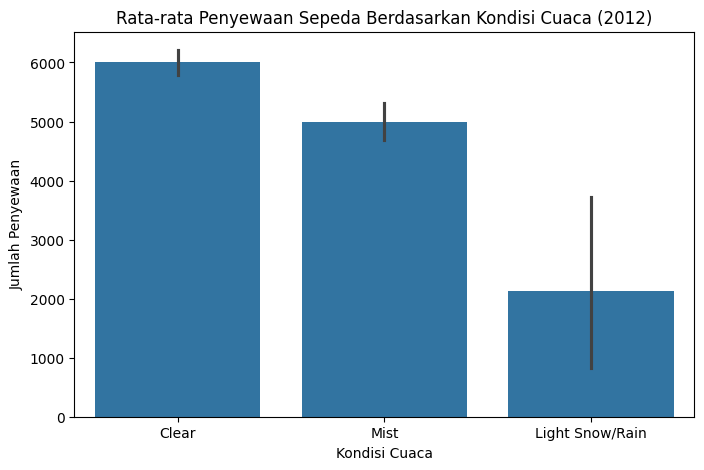

In [89]:
# Visualisasi
plt.figure(figsize=(8,5))
sns.barplot(data=day_df, x='weathersit', y='total_rentals')
plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca (2012)')
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Jumlah Penyewaan')
plt.show()

### Pertanyaan 2:

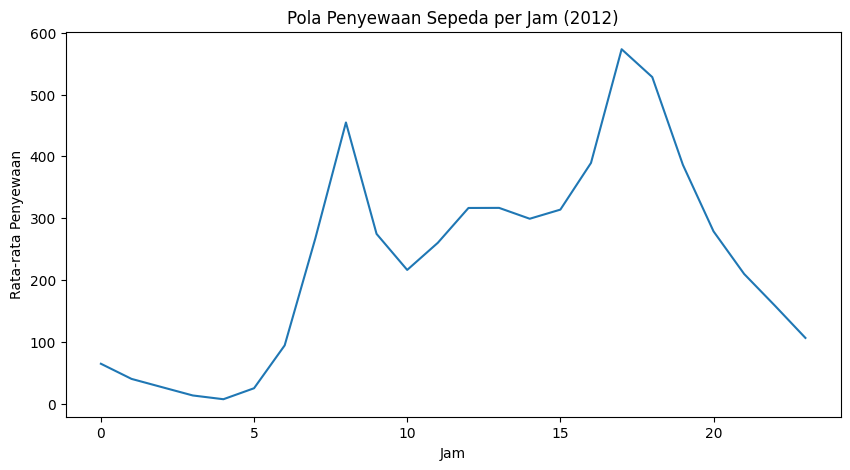

In [90]:
# Visualisasi Pola Jam
hour_avg = hour_df.groupby('hr')['total_rentals'].mean().reset_index()

plt.figure(figsize=(10,5))
sns.lineplot(data=hour_avg, x='hr', y='total_rentals')
plt.title('Pola Penyewaan Sepeda per Jam (2012)')
plt.xlabel('Jam')
plt.ylabel('Rata-rata Penyewaan')
plt.show()

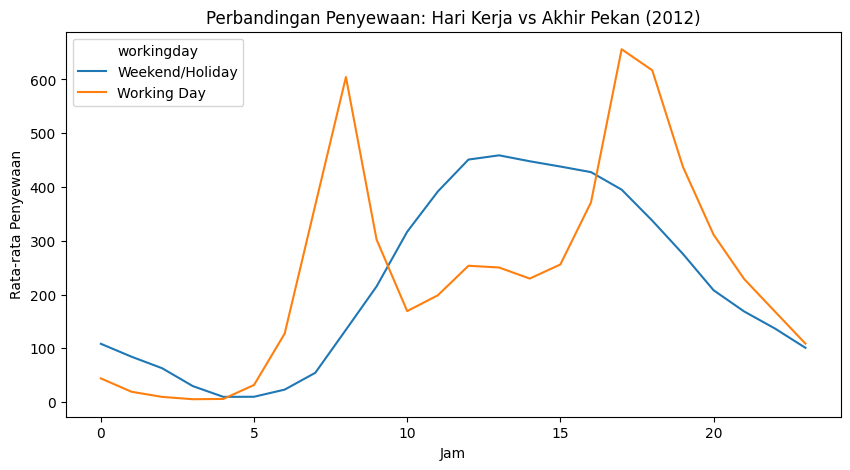

In [91]:
# Visualisasi Working Day vs Weekday
working_avg = hour_df.groupby(['hr','workingday'])['total_rentals'].mean().reset_index()

plt.figure(figsize=(10,5))
sns.lineplot(data=working_avg, x='hr', y='total_rentals', hue='workingday')
plt.title('Perbandingan Penyewaan: Hari Kerja vs Akhir Pekan (2012)')
plt.xlabel('Jam')
plt.ylabel('Rata-rata Penyewaan')
plt.show()

**Insight (Pertanyaan 1) : Pengaruh kondisi cuaca terhadap penyewaan sepeda**
- Berdasarkan visualisasi, terlihat bahwa kondisi cuaca cerah menghasilkan rata-rata penyewaan sepeda tertinggi dibandingkan kondisi kabut dan salju ringan/hujan. Sementara itu, pada kondisi cuaca yang kurang mendukung, jumlah penyewaan mengalami penurunan yang cukup signifikan. Hal ini menunjukkan bahwa kenyamanan dan keamanan dalam berkendara menjadi faktor utama yang memengaruhi keputusan pengguna. Dalam konteks bisnis, pengelola dapat memaksimalkan ketersediaan sepeda saat cuaca cerah untuk meningkatkan pendapatan, serta mempertimbangkan strategi seperti promo atau diskon pada kondisi cuaca kurang baik guna menjaga stabilitas penggunaan.

**Insight (Pertanyaan 2):**
- Pola penyewaan sepeda per jam  
Visualisasi menunjukkan bahwa penyewaan sepeda memiliki pola yang tidak merata sepanjang hari, dengan peningkatan signifikan pada pagi hari sekitar pukul 08.00 dan sore hari sekitar pukul 17.00–18.00. Pola ini mengindikasikan bahwa sepeda banyak digunakan untuk aktivitas rutin seperti berangkat dan pulang kerja. Di luar jam tersebut, jumlah penyewaan cenderung lebih rendah, terutama pada dini hari. Temuan ini dapat dimanfaatkan untuk mengatur distribusi sepeda secara lebih optimal, yaitu dengan menempatkan lebih banyak sepeda pada jam sibuk dan mengurangi penempatan pada jam dengan permintaan rendah.
- Perbandingan penyewaan antara hari kerja dan akhir pekan  
Dari hasil visualisasi, terlihat bahwa pada hari kerja terjadi lonjakan penyewaan yang sangat jelas pada jam sibuk pagi dan sore, sedangkan pada akhir pekan pola penyewaan lebih merata sepanjang hari tanpa lonjakan yang terlalu tajam. Hal ini menunjukkan bahwa pada hari kerja, penggunaan sepeda didominasi oleh kebutuhan mobilitas rutin, sedangkan pada akhir pekan lebih cenderung digunakan untuk aktivitas santai atau rekreasi. Berdasarkan temuan ini, pengelola dapat menerapkan strategi operasional yang berbeda, seperti meningkatkan ketersediaan sepeda di area perkantoran pada hari kerja dan di area rekreasi pada akhir pekan untuk menyesuaikan dengan pola permintaan pengguna.

## Analisis Lanjutan (Clustering berdasarkan tingkat penyewaan sepeda/Demand)

Pada tahap ini dilakukan analisis lanjutan menggunakan teknik clustering sederhana dengan metode binning. Tujuan dari analisis ini adalah untuk mengelompokkan tingkat penyewaan sepeda ke dalam beberapa kategori berdasarkan jumlah penyewaan.

Pengelompokan ini dilakukan untuk mempermudah identifikasi pola permintaan, sehingga dapat diketahui kapan periode dengan permintaan rendah, sedang, dan tinggi. Informasi ini penting dalam membantu pengambilan keputusan terkait pengelolaan distribusi sepeda dan strategi operasional.

Clustering dilakukan dengan membagi data jumlah penyewaan (`cnt`) ke dalam tiga kategori, yaitu Low, Medium, dan High berdasarkan rentang nilai tertentu.

In [92]:
# Membuat kategori demand
hour_df = hour_df.copy()

hour_df['demand_category'] = pd.cut(
    hour_df['total_rentals'],
    bins=3,
    labels=['Low', 'Medium', 'High']
)

hour_df[['total_rentals', 'demand_category']].head()

,total_rentals,demand_category
8645,48,Low
8646,93,Low
8647,75,Low
8648,52,Low
8649,8,Low


In [93]:
# Agregasi 1
hour_df['demand_category'].value_counts()

,count
demand_category,
Low,6335
Medium,1929
High,470


In [94]:
# Agregasi 2
hour_df.groupby('demand_category')['total_rentals'].mean().reset_index()

/tmp/ipykernel_2611/1289878630.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  hour_df.groupby('demand_category')['total_rentals'].mean().reset_index()


,demand_category,total_rentals
0,Low,127.607261
1,Medium,459.017107
2,High,756.893617


In [95]:
# Agregasi 3
hour_df.groupby(['hr', 'demand_category']).size().reset_index(name='count')

/tmp/ipykernel_2611/152215440.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  hour_df.groupby(['hr', 'demand_category']).size().reset_index(name='count')


,hr,demand_category,count
0,0,Low,365
1,0,Medium,0
2,0,High,0
3,1,Low,364
4,1,Medium,0
...,...,...,...
67,22,Medium,2
68,22,High,0
69,23,Low,365
70,23,Medium,0


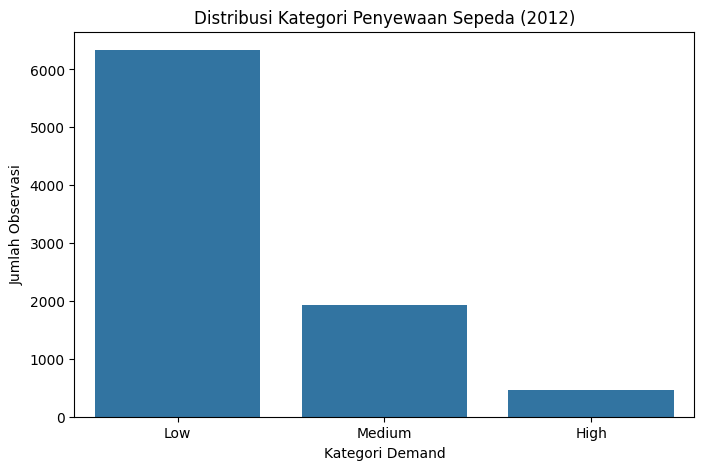

In [96]:
# Visualisasi
plt.figure(figsize=(8,5))
sns.countplot(
    data=hour_df,
    x='demand_category',
    order=['Low','Medium','High']
)
plt.title('Distribusi Kategori Penyewaan Sepeda (2012)')
plt.xlabel('Kategori Demand')
plt.ylabel('Jumlah Observasi')
plt.show()

**Insight(Clustering):**
- Berdasar hasil visualisasi distribusi kategori penyewaan sepeda, bisa kita lihat bahwa mayoritas data berada pada kategori Low, diikuti oleh kategori Medium, dan hanya sebagian kecil yang termasuk dalam kategori High. Hal ini menunjukkan bahwa sebagian besar waktu, tingkat penyewaan sepeda berada pada kondisi permintaan rendah.
- Kategori High yang jumlahnya relatif sedikit mengindikasikan bahwa lonjakan penyewaan hanya terjadi pada waktu-waktu tertentu, yang kemungkinan besar bertepatan dengan jam sibuk seperti pagi dan sore hari. Sementara itu, dominasi kategori Low menunjukkan bahwa terdapat banyak periode dengan pemanfaatan sepeda yang belum optimal.
- Dari perspektif operasional, hal ini memberikan peluang bagi pengelola untuk meningkatkan efisiensi, seperti mengoptimalkan distribusi sepeda agar lebih terfokus pada periode dengan kategori High, serta mengembangkan strategi untuk meningkatkan penggunaan pada periode Low, misalnya melalui promosi, penyesuaian harga, atau peningkatan aksesibilitas layanan.
- Dengan adanya pengelompokan ini, pengelola dapat lebih mudah memahami pola permintaan secara keseluruhan dan mengambil keputusan yang lebih tepat dalam mengelola ketersediaan sepeda.

## Conclusion

- Conclution pertanyaan 1:
- Bagaimana pengaruh kondisi cuaca terhadap jumlah penyewaan sepeda harian selama tahun 2012?
Berdasarkan hasil analisis, kondisi cuaca merupakan faktor yang sangat-sangat berpengaruh signifikan terhadap jumlah penyewaan sepeda, di mana cuaca cerah mendorong peningkatan penyewaan secara optimal. Hal yang sebaliknya terjadi pada cuaca Kabut dan Salju ringan/hujan. Hal ini menunjukkan bahwa permintaan penyewaan sangat dipengaruhi oleh tingkat kenyamanan pengguna dalam beraktivitas. Oleh karena itu, pengelola perlu menyesuaikan strategi operasional dengan kondisi cuaca, seperti meningkatkan ketersediaan sepeda saat cuaca mendukung serta menerapkan strategi khusus pada kondisi cuaca kurang baik untuk menjaga kestabilan permintaan.
- Conclution pertanyaan 2:
- Bagaimana pola penyewaan sepeda berdasarkan waktu (jam) pada hari kerja dan akhir pekan selama tahun 2012?
Hasil analisis menunjukkan bahwa penyewaan sepeda memiliki pola yang terpusat pada jam-jam tertentu, khususnya pada pagi dan sore hari yang berkaitan dengan aktivitas mobilitas harian. Selain itu, terdapat perbedaan pola antara hari kerja dan akhir pekan, di mana hari kerja menunjukkan lonjakan pada jam sibuk, sedangkan akhir pekan cenderung lebih merata. Hal ini mengindikasikan bahwa perilaku pengguna dipengaruhi oleh rutinitas harian dan waktu luang. Dengan demikian, pengelola dapat mengoptimalkan distribusi dan ketersediaan sepeda berdasarkan waktu serta menyesuaikan strategi layanan untuk meningkatkan efisiensi dan kepuasan pengguna.